# Control variates for simulated power spectra: a toy model

**The problem.** A simulation of one box measures $\hat P(k)$ with *sample variance*: at low $k$ there are few modes,
so $\hat P$ scatters around the true mean by $\sim\sqrt{2/N_\mathrm{modes}}$. To beat it you average many seeds,
which is what costs the CPU hours.

**The idea.** Find a second quantity $\hat C(k)$ that

1. is computed from **the same initial conditions** (so it scatters *together* with $\hat P$),
2. is **cheap**, and
3. has a **mean $\langle C\rangle$ we know exactly** (analytically).

Then

$$\hat P_\mathrm{cv}(k) = \hat P(k) - \beta(k)\,\big[\hat C(k) - \langle C(k)\rangle\big]$$

has the **same mean** as $\hat P$ for *any* $\beta$ (the bracket has mean zero), but much less scatter when $\hat P$ and
$\hat C$ are correlated. Its variance is

$$\mathrm{Var}(\hat P_\mathrm{cv}) = \mathrm{Var}(\hat P) - 2\beta\,\mathrm{Cov}(\hat P,\hat C) + \beta^2\,\mathrm{Var}(\hat C),$$

minimised by $\beta^* = \mathrm{Cov}(\hat P,\hat C)/\mathrm{Var}(\hat C)$, which gives
$\mathrm{Var}(\hat P_\mathrm{cv}) = (1-\rho^2)\,\mathrm{Var}(\hat P)$ with $\rho$ the correlation coefficient.
A correlation of $\rho = 0.99$ is worth $1/(1-\rho^2) \approx 50$ simulations; $\rho = 0.999$ is worth 500.

**Here** (Kokron et al. 2022, arXiv:2205.15327): $\hat P$ = the hybrid bias spectra of the COLA simulation,
$\hat C$ = the same spectra of the **Zel'dovich field** of the same initial conditions (the lattice moved with the
1LPT displacement; cheap, no time stepping), and $\langle C\rangle$ = the **analytic Zel'dovich prediction** (resummed
1LPT, computed exactly for the same linear $P(k)$). On large scales the simulation *is* almost the Zel'dovich field,
so $\rho \to 1$ there, exactly where sample variance is worst.

This notebook does the same in 2D with numpy: the "simulation" is 2LPT (it has the mode coupling of real gravity at
second order), the control variate is the Zel'dovich field of the same initial conditions, and $\langle C\rangle$ is
the mean of many cheap Zel'dovich realisations (in FML it is the analytic prediction). Each realisation takes
milliseconds, so we can measure the statistics directly.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

N = 256          # particles per dimension = grid size
L = 256.0        # box size (Mpc/h); 1 Mpc/h per particle, as in production
kf = 2 * np.pi / L
kx = np.fft.fftfreq(N, d=L / N) * 2 * np.pi
ky = np.fft.rfftfreq(N, d=L / N) * 2 * np.pi
KX, KY = np.meshgrid(kx, ky, indexing="ij")
K2 = KX**2 + KY**2
K = np.sqrt(K2)
K2safe = np.where(K2 > 0, K2, 1.0)

def P_lin(k, A=400.0, k0=0.05, kc=0.6):
    # A 2D toy linear spectrum: turns over at k0, cut off at kc (change A to make it more or less nonlinear)
    return A * (k / k0) / (1 + (k / k0)**2.5) * np.exp(-(k / kc)**2)

# k bins and how many modes each has
nbins = 40
edges = np.linspace(kf / 2, np.pi * N / L, nbins + 1)
kbin = 0.5 * (edges[1:] + edges[:-1])
which = np.digitize(K.ravel(), edges) - 1
weight = np.ones_like(K); weight[:, 1:-1] = 2      # rfft: modes with ky > 0 stand for two modes
weight = weight.ravel()
nmodes = np.bincount(which[(which >= 0) & (which < nbins)], weights=weight[(which >= 0) & (which < nbins)], minlength=nbins)
print("modes in the first bins:", nmodes[:5].astype(int))

modes in the first bins: [ 44 100 180 228 300]


## Initial conditions, Zel'dovich and 2LPT

`fixed=True` gives amplitude-fixed initial conditions ($|\delta_k|^2 = P(k)$ exactly, random phases), as your runs use
(`ic_fix_amplitude = true`); `flip=True` reverses the phases (the paired run).

In [2]:
def initial_field(seed, fixed=False, flip=False):
    # delta_L(k) on the rfft grid, normalised so that <|delta_k|^2> L^2 / N^4 = P(k)
    w = np.fft.rfft2(np.random.default_rng(seed).standard_normal((N, N)))
    if fixed:
        w = w / np.maximum(np.abs(w), 1e-30) * N       # unit amplitude, keep the phase
    if flip:
        w = -w
    amp = np.sqrt(P_lin(np.where(K > 0, K, kf)) / L**2) * N
    d = w * amp
    d[0, 0] = 0
    return d

def grad(phi_k):
    # Real-space gradient of a field given in Fourier space
    return [np.fft.irfft2(1j * KX * phi_k, s=(N, N)), np.fft.irfft2(1j * KY * phi_k, s=(N, N))]

def displacements(delta_k):
    # Zel'dovich (1LPT) and second-order (2LPT) displacements, x = q + psi1 + psi2
    phi1 = -delta_k / K2safe                          # nabla^2 phi1 = delta_L
    psi1 = [-g for g in grad(phi1)]
    pxx = np.fft.irfft2(-KX * KX * phi1, s=(N, N)); pyy = np.fft.irfft2(-KY * KY * phi1, s=(N, N))
    pxy = np.fft.irfft2(-KX * KY * phi1, s=(N, N))
    phi2 = -np.fft.rfft2(pxx * pyy - pxy**2) / K2safe  # nabla^2 phi2 = sum_{i<j} (phi_ii phi_jj - phi_ij^2)
    psi2 = [-3.0 / 7.0 * g for g in grad(phi2)]          # D2 = -3/7 D1^2
    return psi1, psi2

q = (np.indices((N, N)) * (L / N)).reshape(2, -1)

def paint(psi, weights=None):
    # CIC density contrast of the particles moved by psi, each carrying 1 + weight (weight = a Lagrangian operator)
    x = (q + np.array([p.ravel() for p in psi])) / (L / N) % N
    i = np.floor(x).astype(int); f = x - i
    w = np.ones(N * N) if weights is None else weights.ravel()
    rho = np.zeros(N * N)
    for dx in (0, 1):
        for dy in (0, 1):
            ww = w * (f[0] if dx else 1 - f[0]) * (f[1] if dy else 1 - f[1])
            np.add.at(rho, ((i[0] + dx) % N) * N + (i[1] + dy) % N, ww)
    return rho.reshape(N, N) - (1.0 if weights is None else 0.0)

def cross_power(a, b):
    ak, bk = np.fft.rfft2(a), np.fft.rfft2(b)
    p = (ak * np.conj(bk)).real.ravel() * weight * L**2 / N**4
    ok = (which >= 0) & (which < nbins)
    return np.bincount(which[ok], weights=p[ok], minlength=nbins) / np.maximum(nmodes, 1)

def operators(delta_k):
    # Lagrangian operators at the particles: 1 (matter), delta_L and delta_L^2 - <delta_L^2>
    d = np.fft.irfft2(delta_k, s=(N, N))
    return {"1": None, "d": d, "d2": d**2 - np.mean(d**2)}

def spectra(seed, fixed=False, flip=False):
    # P_ab of the 2LPT "simulation" and of the Zel'dovich field of the same initial conditions, for ab in 11, 1d, dd, d2d2
    dk = initial_field(seed, fixed, flip)
    psi1, psi2 = displacements(dk)
    ops = operators(dk)
    out = {}
    for name, psi in [("sim", [a + b for a, b in zip(psi1, psi2)]), ("zel", psi1)]:
        f = {o: paint(psi, w) for o, w in ops.items()}
        out[name] = {"11": cross_power(f["1"], f["1"]), "1d": cross_power(f["1"], f["d"]),
                     "dd": cross_power(f["d"], f["d"]), "d2d2": cross_power(f["d2"], f["d2"])}
    return out

s = spectra(0)
print("rms displacement (Mpc/h):", np.std(displacements(initial_field(0))[0][0]).round(2))

rms displacement (Mpc/h): 5.35


## An ensemble

100 seeds of the \"simulation\" with their Zel'dovich fields, and 200 *other* seeds of the Zel'dovich field alone,
whose mean plays the role of the analytic prediction $\langle C\rangle$ (in FML: `hybridbias_zeldovich_z*.txt`).
Takes about two minutes.

In [3]:
nsim, nzel = 100, 200
runs = [spectra(seed) for seed in range(nsim)]
zel_mean = {ab: np.mean([spectra(10000 + s)["zel"][ab] for s in range(nzel)], axis=0)
            for ab in ["11", "1d", "dd", "d2d2"]}
sim = {ab: np.array([r["sim"][ab] for r in runs]) for ab in zel_mean}
zel = {ab: np.array([r["zel"][ab] for r in runs]) for ab in zel_mean}
truth = {ab: sim[ab].mean(0) for ab in sim}

## 1. One realisation

One simulation (grey), the same seed with the control variate ($\beta = 1$, red), and the ensemble mean (black). The
bumps in the single simulation are sample variance; the control variate removes most of them on large scales.

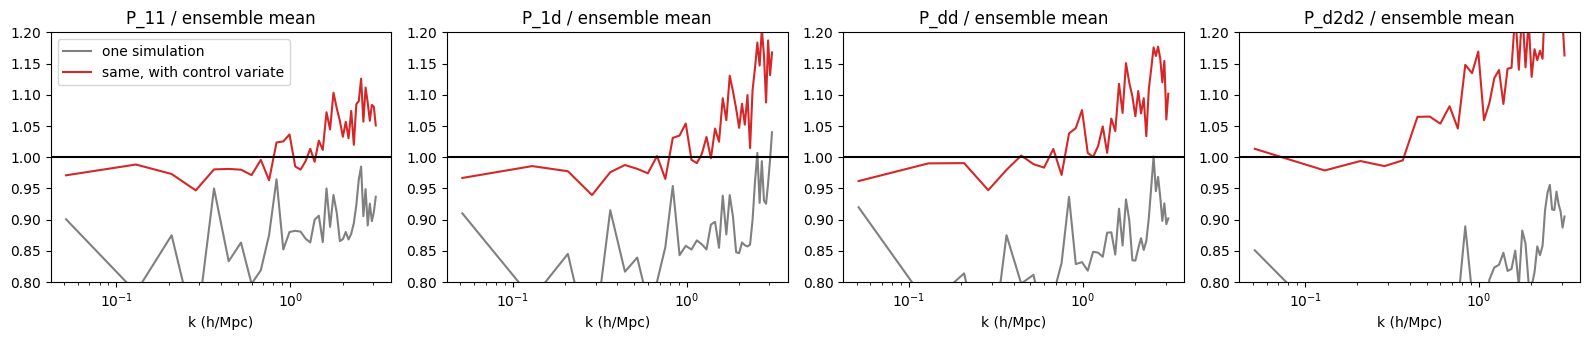

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, ab in zip(axes, sim):
    one, cv = sim[ab][0], sim[ab][0] - (zel[ab][0] - zel_mean[ab])
    ax.plot(kbin, one / truth[ab], color="grey", label="one simulation")
    ax.plot(kbin, cv / truth[ab], color="C3", label="same, with control variate")
    ax.axhline(1, color="k")
    ax.set_xscale("log"); ax.set_title(f"P_{ab} / ensemble mean"); ax.set_ylim(0.8, 1.2); ax.set_xlabel("k (h/Mpc)")
axes[0].legend(); plt.tight_layout()

## 2. How much variance does it remove?

Left: the correlation coefficient $\rho(k)$ between $\hat P$ and $\hat C$ over the seeds. Right: the standard deviation
of the estimate with and without the control variate, for $\beta = 1$ and the optimal $\beta^*(k)$. The ratio
$\sigma^2/\sigma_\mathrm{cv}^2$ is the number of simulations one control-variate run is worth.

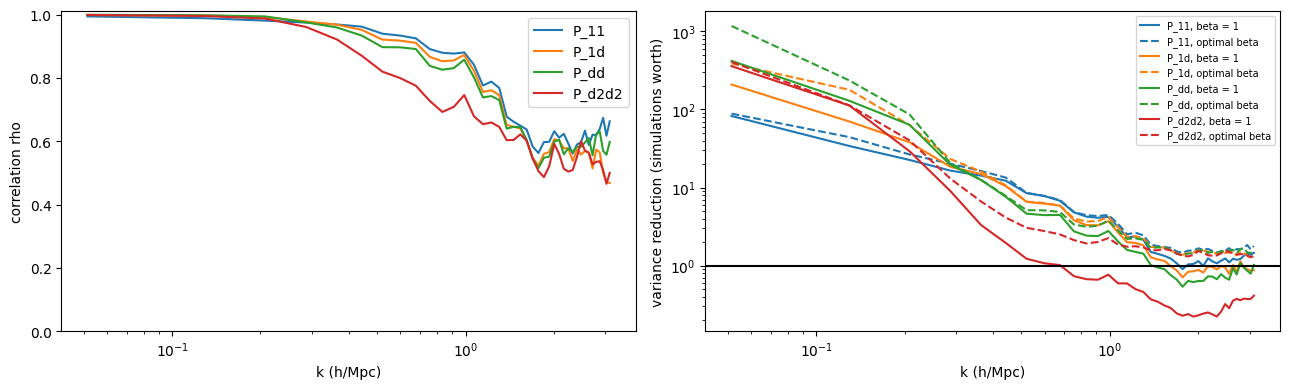

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ab, c in zip(sim, ["C0", "C1", "C2", "C3"]):
    S, C = sim[ab], zel[ab]
    rho = np.array([np.corrcoef(S[:, i], C[:, i])[0, 1] for i in range(nbins)])
    beta = np.array([np.cov(S[:, i], C[:, i])[0, 1] / np.var(C[:, i], ddof=1) for i in range(nbins)])
    axes[0].plot(kbin, rho, color=c, label=f"P_{ab}")
    sd = S.std(0); sd_cv1 = (S - (C - zel_mean[ab])).std(0); sd_opt = (S - beta * (C - zel_mean[ab])).std(0)
    axes[1].plot(kbin, (sd / sd_cv1)**2, color=c, label=f"P_{ab}, beta = 1")
    axes[1].plot(kbin, (sd / sd_opt)**2, color=c, ls="--", label=f"P_{ab}, optimal beta")
axes[0].set(xscale="log", ylabel="correlation rho", xlabel="k (h/Mpc)", ylim=(0, 1.01)); axes[0].legend()
axes[1].set(xscale="log", yscale="log", ylabel="variance reduction (simulations worth)", xlabel="k (h/Mpc)")
axes[1].axhline(1, color="k"); axes[1].legend(fontsize=7); plt.tight_layout()

**What to notice.** On large scales $\rho \to 1$ and one run is worth tens to hundreds of runs. At high $k$ the
simulation and the Zel'dovich field decorrelate (shell crossing, the 2LPT term); with $\beta = 1$ the control
variate there *adds* the Zel'dovich field's own variance and can do worse than nothing (ratio < 1). That is why FML
damps $\beta(k)$ with the filter of Kokron et al. (their Eq. 4.7),
$\beta(k) = \tfrac12[1 - \tanh((k - k_0)/\Delta k)]$ with $k_0 = 0.618$, $\Delta k = 0.167$ h/Mpc (calibrated for 3D
$N$-body at $z = 0$; `hybridbias_zeldovich_cv_beta_k0/_dk`). The estimator stays unbiased for any $\beta(k)$; $\beta$
only decides how much variance is removed.

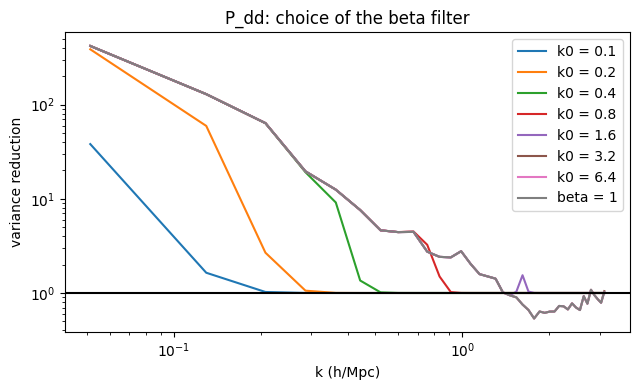

In [8]:
def beta_tanh(k, k0, dk):
    return 0.5 * (1 - np.tanh((k - k0) / dk))

ab = "dd"
S, C = sim[ab], zel[ab]
plt.figure(figsize=(6.5, 4))
for k0 in [0.1, 0.2, 0.4, 0.8, 1.6, 3.2, 6.4, 10]:
    b = beta_tanh(kbin, k0, 0.05) if k0 < 10 else np.ones(nbins)
    plt.plot(kbin, (S.std(0) / (S - b * (C - zel_mean[ab])).std(0))**2, label=f"k0 = {k0}" if k0 < 10 else "beta = 1")
plt.xscale("log"); plt.yscale("log"); plt.axhline(1, color="k"); plt.xlabel("k (h/Mpc)")
plt.ylabel("variance reduction"); plt.title(f"P_{ab}: choice of the beta filter"); plt.legend(); plt.tight_layout()

## 3. The one way to get it wrong: the mean of the control variate

The estimator is unbiased only if $\langle C\rangle$ is the true mean of the Zel'dovich field **as measured** (same
grid, assignment, cut, smoothing, binning). An error $\epsilon$ in $\langle C\rangle$ goes straight into the answer,
$\langle\hat P_\mathrm{cv}\rangle = \langle P\rangle + \beta\,\epsilon$, and it is *not* averaged away by more seeds.
That is why FML computes the prediction with the same spherical cut (`hybridbias_kcut_over_nyquist > 0`), and why its
author checked that 100 Zel'dovich fields average to the prediction to ~0.1%. Below: a 1% error in $\langle C\rangle$.

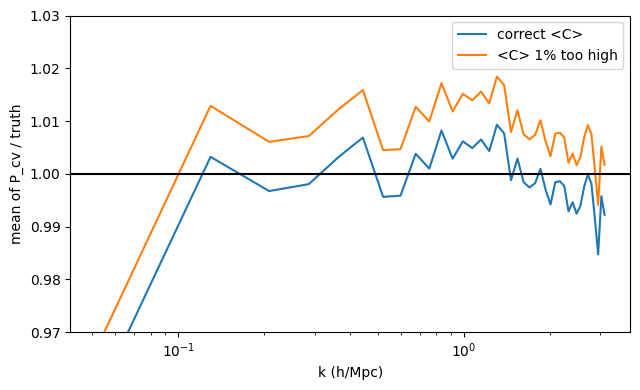

In [9]:
ab = "11"
cv_ok = (sim[ab] - (zel[ab] - zel_mean[ab])).mean(0)
cv_bad = (sim[ab] - (zel[ab] - 1.01 * zel_mean[ab])).mean(0)
plt.figure(figsize=(6.5, 4))
plt.plot(kbin, cv_ok / truth[ab], label="correct <C>")
plt.plot(kbin, cv_bad / truth[ab], label="<C> 1% too high")
plt.axhline(1, color="k"); plt.xscale("log"); plt.ylim(0.97, 1.03); plt.xlabel("k (h/Mpc)")
plt.ylabel("mean of P_cv / truth"); plt.legend(); plt.tight_layout()

## 4. Fixed amplitudes and paired phases

Your runs use amplitude-fixed initial conditions and phase-reversed pairs, which already remove part of the variance.
With fixed amplitudes the *linear* field has no variance left ($|\delta_k|^2 = P$ exactly), so a linear-theory
control variate would do nothing. The Zel'dovich field still varies (its nonlinear part depends on the phases), and
so does the simulation, in the same way: the two tricks combine. Pairing cancels the terms odd in the field;
the control variate removes much of what is left.

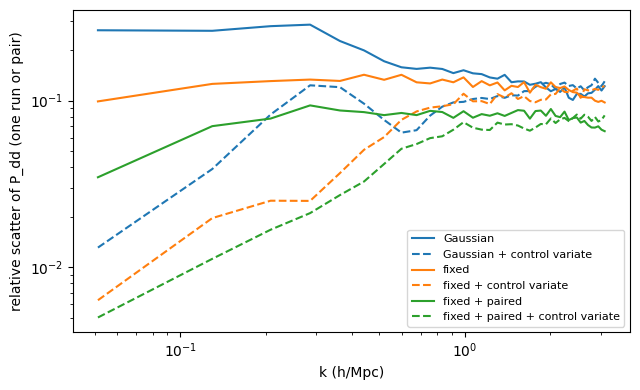

In [10]:
def var_ratio(fixed, paired, ab="dd", n=100):
    est, est_cv = [], []
    for s in range(n):
        r = [spectra(20000 + s, fixed, False)] + ([spectra(20000 + s, fixed, True)] if paired else [])
        P = np.mean([x["sim"][ab] for x in r], 0); Cz = np.mean([x["zel"][ab] for x in r], 0)
        est.append(P); est_cv.append(P - (Cz - zel_mean[ab]))
    return np.std(est, 0), np.std(est_cv, 0)

plt.figure(figsize=(6.5, 4))
for fixed, paired, c in [(False, False, "C0"), (True, False, "C1"), (True, True, "C2")]:
    sd, sd_cv = var_ratio(fixed, paired)
    lab = ("fixed" if fixed else "Gaussian") + (" + paired" if paired else "")
    plt.plot(kbin, sd / truth["dd"], color=c, label=lab)
    plt.plot(kbin, sd_cv / truth["dd"], color=c, ls="--", label=lab + " + control variate")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("k (h/Mpc)"); plt.ylabel("relative scatter of P_dd (one run or pair)")
plt.legend(fontsize=8); plt.tight_layout()

## 5. What this means for the Latin hypercube

* Each cosmology is a **new** simulation, so you can't average seeds per point cheaply. With the control variate, one
  paired run per cosmology has the large-scale precision of many seeds, and the emulator sees smooth spectra instead of
  sample-variance bumps, so it needs fewer points.
* The control variate costs: the Zel'dovich field (~80 s per output at 1024^3, per run) and the analytic prediction
  (~14 min per output at hybridbias_nmesh 1024, **per cosmology**, so also per LHS point). Both are needed per point.
* It needs `hybridbias_kcut_over_nyquist > 0`, the same for every run you compare.
* It does nothing for small scales ($k \gtrsim 0.5$ h/Mpc), where the simulation and Zel'dovich decorrelate; there
  the precision comes from the box volume (and pairing).

**Things to try:** make the field more nonlinear (`A` in `P_lin`) and watch $\rho(k)$ drop; use the linear field as
the control instead of Zel'dovich; estimate $\beta^*$ from 10 seeds instead of 200 (what happens to the variance?);
change the operator ($\delta^2$ has much more shot-noise-like scatter).